# IDA


In [1]:
import pandas as pd
# đọc data train và test từ file csv 

train_df = pd.read_csv("data/fashion-mnist_train.csv")
test_df = pd.read_csv("data/fashion-mnist_test.csv")

# in dòng cột
print("kích thước tập train:", train_df.shape)
print("KíCH thước tập test:", test_df.shape)

kích thước tập train: (60000, 785)
KíCH thước tập test: (10000, 785)


In [2]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


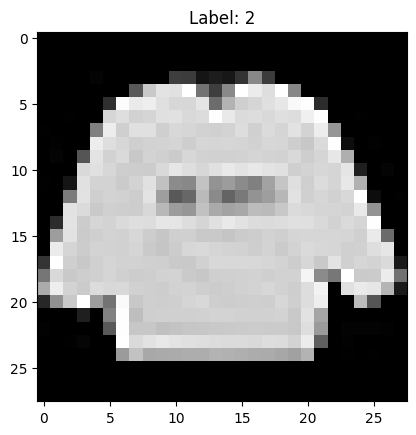

In [7]:
import matplotlib.pyplot as plt

# 1. lấy dòng đầu tiên - dòng 0
first_row = train_df.iloc[0]

# cột first là nhãn (label), 784 số còn lại là pixel
label = first_row['label']
pixels = first_row.drop('label').values

# gop 784 so thanh matrix vuong 28x28
image = pixels.reshape(28, 28)

# ve ảnh lên màn hình 
plt.imshow(image, cmap = 'gray' )
plt.title(f"Label: {label}")
#plt.axis('off') # tắt trục tọa bộ
plt.show()

In [8]:
print("số ô bị trống trong tập train:", train_df.isnull().sum().sum())
print("số ô bị trống trong tập test:", test_df.isnull().sum().sum())

số ô bị trống trong tập train: 0
số ô bị trống trong tập test: 0


In [9]:
train_df['label'].value_counts().sort_index()

label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64

# kết luận IDA

# EDA


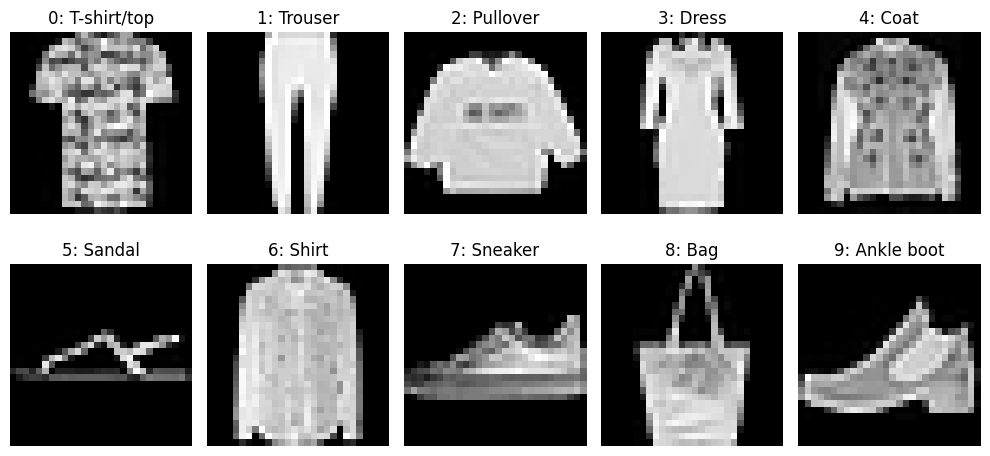

In [25]:
# bảng ánh xạ từ số sáng tên món 
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# tạo khung vẽ 2 hàng, 5 cột chưa đủ 10 món đồ 
plt.figure(figsize=(10,5))

for i in range(10):
    # tìm row đầu tiên của nhãn i 
    sample = train_df[train_df['label']==i].iloc[0]
    img = sample.drop('label').values.reshape (28, 28)
    plt.subplot(2, 5, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(f"{i}: {class_names[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 0, 2, 4, 6 = rất dễ nhầm

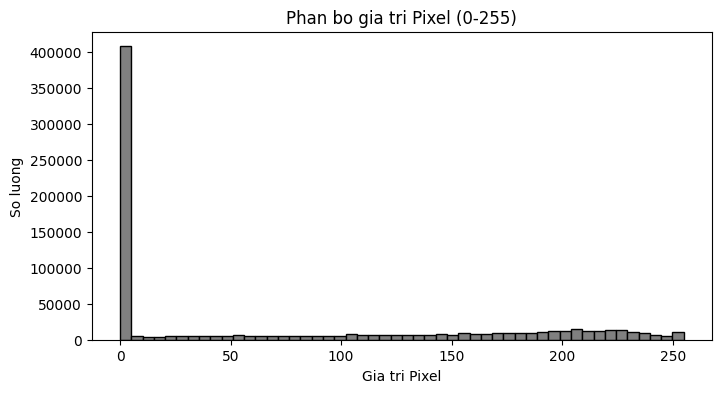

Gia tri nho nhat: 0
Gia tri lon nhat:  255


In [30]:
# Lấy toàn bộ giá trị pixel của 1000 ảnh đầu tiên để vẽ phân bố

sample_pixels = train_df.drop('label', axis=1).iloc[:1000].values.flatten()

plt.figure(figsize=(8,4))
plt.hist(sample_pixels, bins = 50, color = 'gray', edgecolor ='black')
plt.title("Phan bo gia tri Pixel (0-255)")
plt.xlabel("Gia tri Pixel")
plt.ylabel("So luong")
plt.show()

print("Gia tri nho nhat:", sample_pixels.min())
print("Gia tri lon nhat: ", sample_pixels.max())